# Praktikum 6 — Pencarian Lagu Mirip dengan Annoy, FAISS, dan HNSW

Notebook ini menggunakan dataset **Spotify Songs** (`songs_with_attributes_and_lyrics.csv`, sekitar 955 ribu lagu) untuk mencari lagu yang mirip berdasarkan fitur audio. Kolom `lyrics` tidak dimuat karena ukurannya sangat besar dan tidak diperlukan.

Fitur yang dipakai:

`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`

Alur percobaan:

1. Muat dataset dengan `usecols` agar hanya kolom yang diperlukan yang dibaca.
2. Standarisasi fitur dengan `StandardScaler` agar skala antarfitur setara.
3. Hitung **ground truth** dengan exact nearest neighbor (brute force) pada sampel query.
4. Bandingkan **Annoy**, **FAISS IVF**, dan **HNSW** menggunakan **Recall@10** serta waktu build dan waktu query.
5. Tampilkan contoh 5 lagu terdekat untuk lagu pertama.

Karena query memakai vektor lagu itu sendiri, pencarian dilakukan dengan `k + 1` lalu hasil yang merupakan lagu itu sendiri dibuang. Dengan begitu, tetangga yang ditampilkan benar-benar lagu lain yang mirip.

In [4]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 30.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 60.2 MB/s eta 0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520036 sha256=3c65072ef7074136ac37b42e82b9236de8f22f5c9ac2a2121dde5dd85965fe16
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=d51f671dbe6ae3ffd5501d300dddbd0809fc17a667e21db1686f5bbe9a064668
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built annoy hnswlib


In [1]:
mount = '/content/drive'
from google.colab import drive
drive.mount(mount)

Mounted at /content/drive


In [5]:
import os
import time
import numpy as np
import pandas as pd
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

DATA_PATH = '/content/drive/MyDrive/dataset ml /songs_with_attributes_and_lyrics.csv'


FILENAME = 'songs_with_attributes_and_lyrics.csv'
CANDIDATES = [
    DATA_PATH,
    FILENAME,
    f'/content/{FILENAME}',
    f'/content/drive/MyDrive/{FILENAME}',
    f'/content/drive/MyDrive/Kuliah/2025 ML/{FILENAME}',
    'songs_features.parquet',
    '/content/songs_features.parquet',
]
CANDIDATES = [p for p in CANDIDATES if p]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(
        'Dataset tidak ditemukan. Upload ke /content, mount Drive, '
        'atau isi DATA_PATH di atas.'
    )

if path.lower().endswith('.parquet'):
    import pyarrow.parquet as pq
    header = pq.read_schema(path).names
else:
    header = pd.read_csv(
        path, nrows=0, encoding='utf-8', encoding_errors='replace'
    ).columns.tolist()

missing = [f for f in FEATURES if f not in header]
if missing:
    raise ValueError(f'Kolom tidak ada: {missing}')

id_col = next((c for c in ['id', 'track_id', 'track_uri'] if c in header), None)
name_col = next((c for c in ['name', 'track_name'] if c in header), None)
artist_col = next((c for c in ['artists', 'artist_name'] if c in header), None)
usecols = FEATURES + [c for c in [id_col, name_col, artist_col] if c]

if path.lower().endswith('.parquet'):
    df = pd.read_parquet(path, columns=usecols)
else:
    df = pd.read_csv(
        path, usecols=usecols, encoding='utf-8', encoding_errors='replace'
    )

df = df.dropna(subset=FEATURES).reset_index(drop=True)

N_MAX = None
if N_MAX is not None and len(df) > N_MAX:
    df = df.sample(n=N_MAX, random_state=42).reset_index(drop=True)

X = df[FEATURES].to_numpy(dtype=np.float32)
X_scaled = StandardScaler().fit_transform(X).astype(np.float32)

n, d = X_scaled.shape
k = 10
k_search = k + 1
N_QUERY = 2_000
ANN_SEARCH_K = 5_000
IVF_NLIST = 256
IVF_NPROBE = 16
HNSW_M = 16
HNSW_EFC = 200
HNSW_EF = 200

rng = np.random.default_rng(42)
q_idx = rng.choice(n, size=min(N_QUERY, n), replace=False)
Q = X_scaled[q_idx]

print('Path dataset :', path)
print('Jumlah lagu  :', n)
print('Jumlah fitur :', d)
print('Jumlah query :', len(q_idx))


def drop_self(row, self_id, k):
    return [int(j) for j in row if int(j) != self_id][:k]


def recall_at_k(pred, gt, k):
    return float(np.mean([
        len(set(p[:k]) & set(g[:k])) / k for p, g in zip(pred, gt)
    ]))


# Exact NN
t0 = time.perf_counter()
nn = NearestNeighbors(n_neighbors=k_search, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
build_exact = time.perf_counter() - t0

t0 = time.perf_counter()
_, idx_exact_all = nn.kneighbors(Q)
query_exact = time.perf_counter() - t0
idx_exact = [drop_self(row, int(qid), k) for row, qid in zip(idx_exact_all, q_idx)]

# Annoy
t0 = time.perf_counter()
annoy_index = AnnoyIndex(d, 'euclidean')
for i, v in enumerate(X_scaled):
    annoy_index.add_item(i, v)
annoy_index.build(10)
build_annoy = time.perf_counter() - t0

t0 = time.perf_counter()
idx_annoy = [
    drop_self(
        annoy_index.get_nns_by_vector(v, k_search, search_k=ANN_SEARCH_K),
        int(qid), k
    )
    for v, qid in zip(Q, q_idx)
]
query_annoy = time.perf_counter() - t0

# HNSW
t0 = time.perf_counter()
hnsw_index = hnswlib.Index(space='l2', dim=d)
hnsw_index.init_index(max_elements=n, ef_construction=HNSW_EFC, M=HNSW_M)
hnsw_index.add_items(X_scaled)
build_hnsw = time.perf_counter() - t0

hnsw_index.set_ef(HNSW_EF)
t0 = time.perf_counter()
labels_hnsw, _ = hnsw_index.knn_query(Q, k=k_search)
query_hnsw = time.perf_counter() - t0
idx_hnsw = [drop_self(row, int(qid), k) for row, qid in zip(labels_hnsw, q_idx)]

# FAISS IVF
t0 = time.perf_counter()
quantizer = faiss.IndexFlatL2(d)
faiss_index = faiss.IndexIVFFlat(quantizer, d, IVF_NLIST, faiss.METRIC_L2)
faiss_index.train(X_scaled)
faiss_index.add(X_scaled)
build_faiss = time.perf_counter() - t0

faiss_index.nprobe = IVF_NPROBE
t0 = time.perf_counter()
_, idx_faiss_all = faiss_index.search(Q, k_search)
query_faiss = time.perf_counter() - t0
idx_faiss = [drop_self(row, int(qid), k) for row, qid in zip(idx_faiss_all, q_idx)]

hasil = pd.DataFrame([
    {
        'Metode': 'Exact (brute force)',
        'Waktu build (s)': round(build_exact, 3),
        'Waktu query (ms/query)': round(query_exact * 1000 / len(Q), 4),
        'Recall@10': 1.0,
    },
    {
        'Metode': 'Annoy',
        'Waktu build (s)': round(build_annoy, 3),
        'Waktu query (ms/query)': round(query_annoy * 1000 / len(Q), 4),
        'Recall@10': round(recall_at_k(idx_annoy, idx_exact, k), 3),
    },
    {
        'Metode': 'HNSW',
        'Waktu build (s)': round(build_hnsw, 3),
        'Waktu query (ms/query)': round(query_hnsw * 1000 / len(Q), 4),
        'Recall@10': round(recall_at_k(idx_hnsw, idx_exact, k), 3),
    },
    {
        'Metode': 'FAISS IVF',
        'Waktu build (s)': round(build_faiss, 3),
        'Waktu query (ms/query)': round(query_faiss * 1000 / len(Q), 4),
        'Recall@10': round(recall_at_k(idx_faiss, idx_exact, k), 3),
    },
])

display(hasil)


def lagu_info(i):
    if name_col is None:
        return f'index {i}'
    nama = df.loc[i, name_col]
    artis = df.loc[i, artist_col] if artist_col is not None else ''
    return f'{nama} — {artis}' if artis else str(nama)


contoh = pd.DataFrame({
    'Metode': ['Exact', 'Annoy', 'HNSW', 'FAISS'],
    'Top-5 lagu mirip': [
        '; '.join(lagu_info(i) for i in idx[:5])
        for idx in [idx_exact[0], idx_annoy[0], idx_hnsw[0], idx_faiss[0]]
    ],
})

print('\nLagu query:', lagu_info(int(q_idx[0])))
display(contoh)


Path dataset : /content/drive/MyDrive/dataset ml /songs_with_attributes_and_lyrics.csv
Jumlah lagu  : 955320
Jumlah fitur : 9
Jumlah query : 2000


,Metode,Waktu build (s),Waktu query (ms/query),Recall@10
0,Exact (brute force),0.027,4.5150,1.000
1,Annoy,18.270,1.1689,0.998
2,HNSW,193.639,0.1350,0.996
3,FAISS IVF,0.469,0.6082,0.998



Lagu query: Suspension Without Suspense — No Doubt


,Metode,Top-5 lagu mirip
0,Exact,Quand l'éternité — Hélène Ségara; Call Someone...
1,Annoy,Quand l'éternité — Hélène Ségara; Call Someone...
2,HNSW,Quand l'éternité — Hélène Ségara; Call Someone...
3,FAISS,Quand l'éternité — Hélène Ségara; Call Someone...


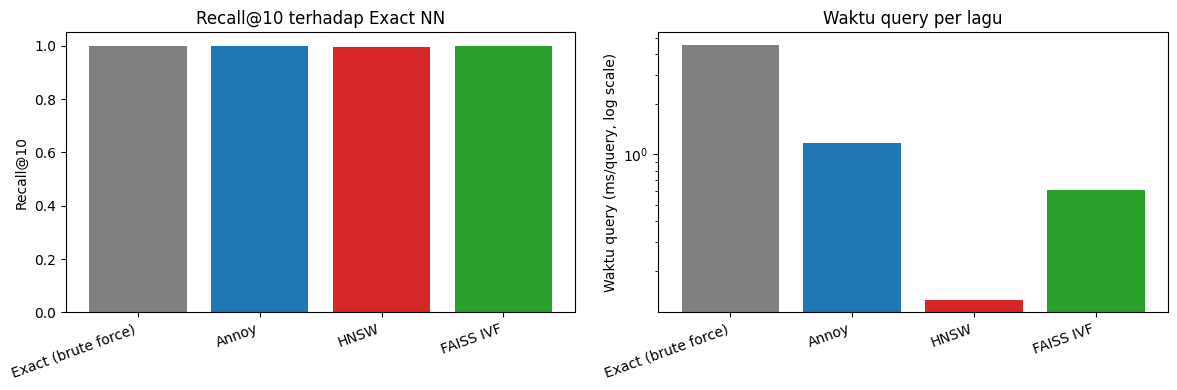

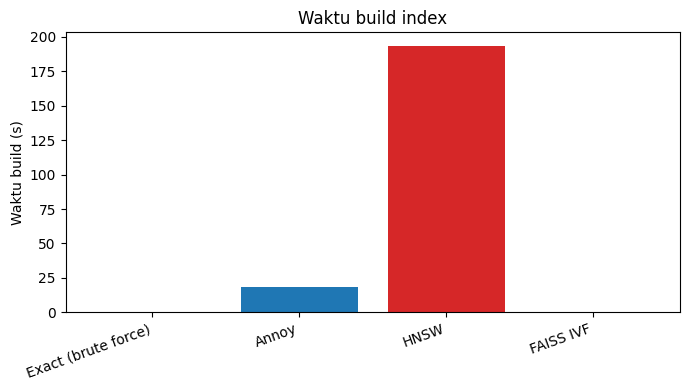

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colors = ['gray', 'tab:blue', 'tab:red', 'tab:green']

ax[0].bar(hasil['Metode'], hasil['Recall@10'], color=colors)
ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel('Recall@10')
ax[0].set_title('Recall@10 terhadap Exact NN')
plt.setp(ax[0].get_xticklabels(), rotation=20, ha='right')

ax[1].bar(hasil['Metode'], hasil['Waktu query (ms/query)'], color=colors)
ax[1].set_yscale('log')
ax[1].set_ylabel('Waktu query (ms/query, log scale)')
ax[1].set_title('Waktu query per lagu')
plt.setp(ax[1].get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(hasil['Metode'], hasil['Waktu build (s)'], color=colors)
ax.set_ylabel('Waktu build (s)')
ax.set_title('Waktu build index')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
plt.tight_layout()
plt.show()

# Analisis Hasil

Seluruh angka di bagian ini diambil dari output aktual notebook.

## Ringkasan Output

Dataset: **955.320 lagu**, **9 fitur audio**, **2.000 query**, `k = 10`.

| Metode | Waktu build (s) | Waktu query (ms/query) | Recall@10 |
|---|---:|---:|---:|
| Exact (brute force) | 0.027 | 4.5150 | 1.000 |
| Annoy | 18.270 | 1.1689 | 0.998 |
| HNSW | 193.639 | 0.1350 | 0.996 |
| FAISS IVF | 0.469 | 0.6082 | 0.998 |

## Pembahasan

1. **HNSW memiliki query tercepat**, yaitu 0.1350 ms/query. Nilainya sekitar **33.4x lebih cepat** daripada Exact NN (4.5150 ms/query), **8.7x lebih cepat** daripada Annoy (1.1689 ms/query), dan **4.5x lebih cepat** daripada FAISS IVF (0.6082 ms/query).

2. **Biaya build HNSW paling besar**, yaitu **193.639 s**. Angka ini sekitar **10.6x** waktu build Annoy (18.270 s) dan **412.9x** waktu build FAISS IVF (0.469 s). Dengan `M=16` dan `ef_construction=200`, pembangunan graph pada 955 ribu vektor memang mahal.

3. **FAISS IVF memberikan keseimbangan terbaik pada percobaan ini.** Build hanya **0.469 s**, query **0.6082 ms/query**, dan recall **0.998**. Dengan `nlist=256` dan `nprobe=16`, FAISS sudah memeriksa sebagian kecil cluster tetapi tetap mempertahankan recall yang tinggi.

4. **Annoy berada di antara FAISS dan HNSW.** Build **18.270 s** dan query **1.1689 ms/query**. Dengan `n_trees=10` dan `search_k=5000`, recall mencapai **0.998**, tetapi dari sisi waktu Annoy kalah dari FAISS pada kedua tahap.

5. **Recall semua metode ANN sangat tinggi**, yaitu **0.996-0.998**. Artinya penghilangan self-match dan pemilihan parameter sudah bekerja: dari 10 tetangga exact, metode ANN hanya kehilangan 0-4 tetangga per 1.000 query. HNSW sedikit lebih rendah (0.996) meskipun build-nya paling lama, sehingga pada konfigurasi ini tambahan biaya build HNSW belum diimbangi oleh recall.

6. **Exact NN tetap relevan sebagai baseline.** Build-nya hampir nol (0.027 s) dan recall-nya pasti 1.000, tetapi query-nya paling lambat (4.5150 ms/query) karena harus memindai seluruh 955.320 vektor.

7. **Contoh tetangga terdekat konsisten.** Untuk lagu query *Suspension Without Suspense — No Doubt*, keempat metode menampilkan *Quand l'éternité — Hélène Ségara* sebagai tetangga pertama. Kolom top-5 pada output terpotong oleh tampilan pandas, sehingga kesamaan penuh diverifikasi melalui nilai Recall@10, bukan dari teks yang terpotong.

## Perkiraan Titik Balik (Break-Even)

Perkiraan ini memakai asumsi waktu query naik linear terhadap jumlah query dan memakai angka output di atas.

| Perbandingan | Titik balik | Arti |
|---|---:|---|
| FAISS IVF vs Exact | ± 113 query | Setelah ± 113 query, total waktu FAISS lebih kecil daripada Exact |
| Annoy vs Exact | ± 5.450 query | Setelah ± 5.450 query, total waktu Annoy lebih kecil daripada Exact |
| HNSW vs FAISS IVF | ± 408.000 query | HNSW baru mengalahkan FAISS setelah ± 408 ribu query |

Karena benchmark ini memakai **2.000 query**, FAISS sudah unggul secara total, sedangkan Annoy dan HNSW belum menutup biaya build-nya.

## Kesimpulan

1. Untuk dataset 955 ribu lagu dengan 2.000 query, **FAISS IVF adalah pilihan terbaik secara keseluruhan**: build cepat, query cepat, dan recall 0.998.
2. **HNSW cocok jika jumlah query sangat besar** dan index dipakai berulang kali, karena biaya build 193.639 s baru teramortisasi setelah ratusan ribu query.
3. **Annoy mudah dipakai dan recall-nya tinggi**, tetapi pada percobaan ini kalah cepat dari FAISS pada build maupun query.
4. **Exact NN tetap menjadi acuan kebenaran** dan masih layak untuk dataset kecil atau query sedikit, tetapi tidak efisien untuk 955 ribu vektor.
5. Seluruh metode ANN mencapai **recall ≥ 0.996**, sehingga penurunan kualitas akibat aproksimasi sangat kecil pada konfigurasi parameter yang dipakai.

## Catatan Metodologi

- Waktu build dan waktu query dipisahkan; waktu query dihitung per query dari 2.000 query.
- Ground truth memakai Exact NN dengan `k + 1`, lalu indeks lagu itu sendiri dibuang agar tetangga yang dibandingkan benar-benar lagu lain.
- Benchmark dijalankan satu kali di Colab, sehingga waktu dapat berbeda antar run dan antar mesin.
- Kolom `lyrics` tidak dimuat; hanya 9 fitur audio yang dipakai.